## Mass Test SANOS

In [1]:


%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.utils.arbfree
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.arbfree
%aimport quantdata.widb.options_filter
%aimport quantdata.widb.timeseries

from datetime import date
from quantdata.widb.timeseries import build_time_series, TimeSeriesDefinition, ExpiryFilter, RawDayFilter, OptionsFilter, DateRange, PoolConfig, table_of_time_series, MkArbFree
from quantdata.biz_calendar import next_business_day
from cdxcore.util import fmt_date, fmt_dict
from cdxcore.verbose import Context
from IPython.display import display

def get_times_series(ticker):
    include_fields = {'pure_strike',
                      'pure_ask_price','pure_bid_price',
                      'tte_y','ask_vol','bid_vol','is_valid'}

    time_series_def = TimeSeriesDefinition(
        raw_day_filter = RawDayFilter(),
        expiry_filter = ExpiryFilter(),
        mk_arb_free = None,
        options_filter = OptionsFilter()
    )
    date_range = DateRange(start=date(2015, 1, 1), end=date(2025, 8, 1)) 
    pool_config = PoolConfig(num_workers=0, threading=False)
    verbose = Context.all
    samples = build_time_series(ticker, date_range, include_fields=include_fields, exclude_fields=None, time_series_def=time_series_def, pool_config=pool_config, verbose=verbose, override_cache_mode="on" )
    return samples

ticker = "SPX"
time_series = get_times_series(ticker)
verbose = Context.all
verbose.write(str(table_of_time_series(time_series)))
print("/done")

00: +----------------+--------------+---------+-----------+---------+---------+-----------+--------+
00: |     Field      |    Shape     |  Dtype  |    Size   |   Mean  |   Std   |    Min    |  Max   |
00: +----------------+--------------+---------+-----------+---------+---------+-----------+--------+
00: |     dates      |   (2638,)    |   date  |           |         |         |           |        |
00: |    ask_vol     | (2638, 1000) | float32 |  10.06MB  |  0.1671 | 0.06786 |  0.04179  | 1.507  |
00: |    bid_vol     | (2638, 1000) | float32 |  10.06MB  |  0.1647 | 0.06655 |  0.03551  | 1.411  |
00: |    is_valid    | (2638, 1000) |   bool  | 2576.17KB |  0.9076 |  0.2895 |     0     |   1    |
00: | pure_ask_price | (2638, 1000) | float32 |  10.06MB  | 0.03268 | 0.03339 | 7.958e-05 | 0.4671 |
00: | pure_bid_price | (2638, 1000) | float32 |  10.06MB  | 0.03241 | 0.03318 | 5.657e-05 | 0.4608 |
00: |  pure_strike   | (2638, 1000) | float32 |  10.06MB  |  0.9921 | 0.04156 |   0.5511  |

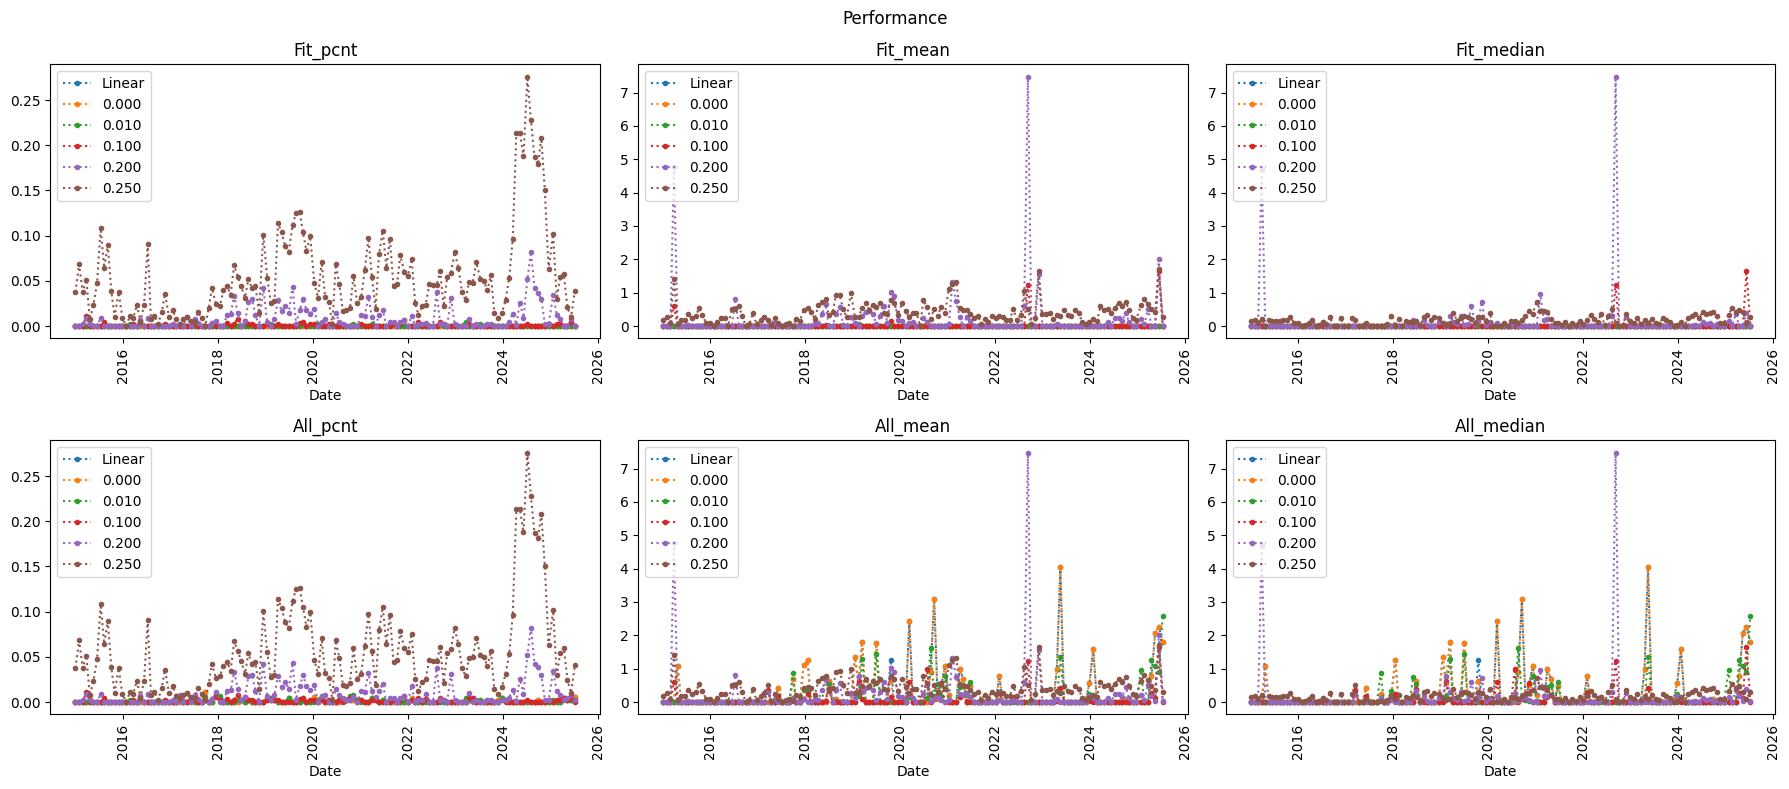

Progress: 1/834 (0.12%) - Date: 2015-01-02, Smoothness: None, Fit mean: 0 [0/373], All mean: 0 [0/373]
Progress: 2/834 (0.24%) - Date: 2015-03-26, Smoothness: None, Fit mean: 0 [0/467], All mean: 0 [0/467]
Progress: 3/834 (0.36%) - Date: 2015-01-30, Smoothness: None, Fit mean: 0 [0/467], All mean: 0 [0/467]
Progress: 4/834 (0.48%) - Date: 2015-02-27, Smoothness: None, Fit mean: 0 [0/535], All mean: 0 [0/535]
Progress: 5/834 (0.60%) - Date: 2015-04-23, Smoothness: None, Fit mean: 0 [0/403], All mean: 1.093 [1/405]
Progress: 6/834 (0.72%) - Date: 2015-05-20, Smoothness: None, Fit mean: 0 [0/396], All mean: 0 [0/396]
Progress: 7/834 (0.84%) - Date: 2015-06-17, Smoothness: None, Fit mean: 0 [0/445], All mean: 0 [0/445]
Progress: 8/834 (0.96%) - Date: 2015-07-15, Smoothness: None, Fit mean: 0 [0/452], All mean: 0 [0/452]
Progress: 9/834 (1.08%) - Date: 2015-09-08, Smoothness: None, Fit mean: 0 [0/368], All mean: 0 [0/368]
Progress: 10/834 (1.20%) - Date: 2015-08-11, Smoothness: None, Fit me

In [2]:
from cdxcore.jcpool import JCPool
from cdxcore.pretty import PrettyObject
import numpy as np
from prettytable import PrettyTable
from cdxcore.subdir import SubDir
from cdxcore.uniquehash import named_unique_filename48_8
from cdxcore.dynaplot import figure, color_tableau

smoothnesses = [None, 0.0, 0.01, 0.1, 0.2, 0.25 ]

_cache = SubDir("!/tmp/arbfree_cache")

@_cache.cache("0.1", uid = lambda ticker, d, smoothness: f"{ticker}/{named_unique_filename48_8(f'{d} {smoothness:4f}' if not smoothness is None else str(d),d,smoothness)}")
def fit_arb_free( ticker, d, smoothness, ddata ):
    expiries = ddata['expiries']
    bids     = ddata['bids']
    asks     = ddata['asks']
    strikes  = ddata['strikes']
    mk_af    = MkArbFree(smoothness=smoothness, surface_expiry_linear=True)
    af       = mk_af( expiries=expiries,
                      strikes=strikes,
                      bids=bids,
                      asks=asks,
                      verbose=Context.quiet  )

    # error on the strikes we think we can fit
    Taf      = len(af.expiries)
    af.errsX = []
    for t in range(Taf):
        masks_t = af.masks[t]
        fitX_t  = af.fitsX[t][masks_t]
        bids_t  = bids[t][masks_t]
        asks_t  = asks[t][masks_t]
        hs_t    = np.maximum( (asks_t - bids_t)/2., mk_af.min_half_spread )
        errX    = ( np.maximum( 0., fitX_t - asks_t ) + np.maximum( 0., bids_t - fitX_t )  ) / hs_t
        af.errsX.append( errX )
        del errX, hs_t, asks_t, bids_t, fitX_t, masks_t

    # errors on all strikes
    af.input_strikes  = strikes
    af.input_bids     = bids
    af.input_asks     = asks
    af.input_expiries = expiries
    af.input_fitsX    = []
    af.input_errsX    = []
    T = len(bids)

    for t in range(T):
        fitX_t = af.price( expiry=expiries[t], strikes=strikes[t], mode="surface" )
        bids_t = bids[t]
        asks_t = asks[t]
        hs_t   = np.maximum( (asks_t - bids_t)/2., mk_af.min_half_spread )
        errX = ( np.maximum( 0., fitX_t - asks_t ) + np.maximum( 0., bids_t - fitX_t )  ) / hs_t
        af.input_fitsX.append( fitX_t )
        af.input_errsX.append( errX )
        del fitX_t, hs_t, asks_t, bids_t, errX

    # stats
    errsX      = np.concatenate( af.errsX )
    inp_errsX  = np.concatenate( af.input_errsX )

    def stats(err):
        r = PrettyObject()
        r.err_cnt = np.sum(err>0.)
        r.total_cnt = len(err)
        r.pcnt = float(r.err_cnt) / float(max(1,r.total_cnt))
        r.mean = np.mean(err)
        r.median = np.median(err)
        r.mean_pos = np.mean(err[err>0.]) if np.any(err>0) else 0.
        r.median_pos = np.median(err[err>0]) if np.any(err>0) else 0.
        r.max = np.max(err)
        return r

    af.stats = stats(errsX)
    af.input_stats = stats(inp_errsX)
    af.ticker = ticker
    af.date = d

    return af        

def block_data(time_series, idd ):

    is_valid_t = time_series['pure_strike'][idd,:].astype(bool, copy=False)
    strikes_t  = time_series['pure_strike'][idd,:][is_valid_t]
    ixs        = np.argsort(strikes_t)
    strikes_t  = strikes_t[ixs]
    bids_t     = time_series['pure_bid_price'][idd,:][is_valid_t][ixs]
    asks_t     = time_series['pure_ask_price'][idd,:][is_valid_t][ixs]
    tte_yt     = time_series['tte_y'][idd,:][is_valid_t][ixs]
    del is_valid_t

    ddata = PrettyObject()
    ddata.expiries = []
    ddata.strikes = []
    ddata.asks = []
    ddata.bids = []

    uttys = np.unique(tte_yt)
    for utty in uttys:
        mask = tte_yt == utty
        if np.sum(mask) == 0:
            continue
        ddata.expiries.append(utty)
        ddata.strikes.append(np.asarray(strikes_t[mask]))
        ddata.asks.append(np.asarray(asks_t[mask]))
        ddata.bids.append(np.asarray(bids_t[mask]))

    return ddata

def mass_fit(ticker, time_series):
    pool = JCPool(num_workers=4, threading=False)

    results = {}

    dates   = time_series['dates']
    results = {}
    skip    = 19
    dates   = dates[::skip]

    total   = len(smoothnesses) * len(dates)
    cnt     = 0

    perf_dates     = [ [] for _ in smoothnesses ]
    perf = PrettyObject()
    perf.fit_pcnt   = [ [] for _ in smoothnesses ]
    perf.fit_mean   = [ [] for _ in smoothnesses ]
    perf.fit_median = [ [] for _ in smoothnesses ]
    perf.all_pcnt   = [ [] for _ in smoothnesses ]
    perf.all_mean   = [ [] for _ in smoothnesses ]
    perf.all_median = [ [] for _ in smoothnesses ]

    with figure("Performance", row_size=4, col_size=6, columns=3) as fig:
        axs = { stat :  fig.add_subplot(stat[0].upper() + stat[1:]) for stat in perf }
        for ax in axs.values():
            ax.set_xlabel("Date")
            ax.tick_params(axis="x", labelrotation=90)   # vertical

        stores = [ fig.store() for _ in smoothnesses ]
        fig.render()

        for (ismth, d), af in pool.parallel( { (ismth, d) : pool.delayed(fit_arb_free)( ticker=ticker, d=d, smoothness=smth, ddata=block_data(time_series, idd), override_cache_mode="update" ) for ismth, smth in enumerate(smoothnesses) for idd, d in enumerate(dates) } ):
            cnt += 1
            results[(af.date,ismth)] = af

            perf_dates[ismth].append(af.date)
            perf.fit_pcnt[ismth].append(af.stats.pcnt)
            perf.fit_mean[ismth].append(af.stats.mean_pos)
            perf.fit_median[ismth].append(af.stats.median_pos)
            perf.all_pcnt[ismth].append(af.input_stats.pcnt)
            perf.all_mean[ismth].append(af.input_stats.mean_pos)
            perf.all_median[ismth].append(af.input_stats.median_pos)

            print(f"Progress: {cnt}/{total} ({(100.0*cnt)/float(total):.2f}%) - Date: {af.date}, Smoothness: {af.smoothness}, Fit mean: {af.stats.mean_pos:.4g} [{af.stats.err_cnt}/{af.stats.total_cnt}], All mean: {af.input_stats.mean_pos:.4g} [{af.input_stats.err_cnt}/{af.input_stats.total_cnt}]")

            perf_dates_i = np.array(perf_dates[ismth])
            ixs          = np.argsort(perf_dates_i)
            perf_dates_i = perf_dates_i[ixs]
            col          = color_tableau(ismth)
            stores[ismth].clear()

            for stat, values in perf.items():
                ax            = axs[stat]
                values        = np.array(values[ismth])[ixs]
                stores[ismth] += ax.plot( perf_dates_i, values, ".:", color=col, label=f"{af.smoothness:.3f}" if not af.smoothness is None else "Linear" )
                ax.legend(loc="upper left")
            fig.render()
    return results

results = mass_fit(ticker, time_series)



